# Hanle Large-Scale AWS Wind Data Analysis (6-Year Dataset)

This notebook performs a comprehensive wind analysis on the consolidated 6-year Automatic Weather Station (AWS) dataset for Hanle (January 2020 to July 2025).

### Contents:
1. **Data Loading:** Loading and downsampling monthly CSV files to ensure high performance and low memory consumption.
2. **Overall Statistics:** Summary statistics of temperature, humidity, wind speed, and direction.
3. **Cumulative Wind Rose:** A polar scatter wind rose showing the overall wind distribution.
4. **Monthly Wind Roses (Separate for Each Year):** Side-by-side monthly wind roses (Jan-Dec) grouped separately for each year.
5. **Resampled Timeseries:** Multi-year wind speed and gust (daily maximum) timeseries.
6. **Seasonal Diurnal Profiles:** Daily wind speed variations across the India Meteorological Department (IMD) official seasons.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Set plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1. Load the Processed Dataset (Memory-Optimized)

The full 6-year dataset contains over 38 million rows. To ensure the notebook is fast and stays well within memory limits, we:
1. Downsample the data for wind roses and diurnal plots by taking every 100th record (~5-minute resolution).
2. Resample the data to daily values on-the-fly during file loading to create a lightweight daily dataframe for timeseries plotting.
3. Use explicit copies and Python's garbage collector (`gc.collect()`) inside the load loop to free large text-parsing buffers immediately.

In [2]:
processed_dir = r"../../data/processed/hanle_published"
csv_files = sorted(glob.glob(os.path.join(processed_dir, "hanle_published_*.csv")))
print(f"Found {len(csv_files)} monthly files to merge.")

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Pre-Monsoon'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

rose_dfs = []
daily_dfs = []

import gc
for f in csv_files:
    # Read CSV
    df_m = pd.read_csv(f)
    
    # Take copy of downsampled slice to free reference to original big block
    rose_dfs.append(df_m.iloc[::100].copy())
    
    # Resample to daily on-the-fly
    df_m['datetime_ist'] = pd.to_datetime(df_m['datetime_ist'])
    df_m_idx = df_m.set_index('datetime_ist')
    m_mean = df_m_idx['wind_speed'].resample('1D').mean()
    m_max = df_m_idx['wind_speed'].resample('1D').max()
    m_temp = df_m_idx['temperature'].resample('1D').mean()
    
    daily_dfs.append(pd.DataFrame({
        'wind_speed_mean': m_mean,
        'wind_speed_max': m_max,
        'temperature_mean': m_temp
    }))
    
    # Explicit clean up to prevent memory leak
    del df_m
    del df_m_idx
    gc.collect()

df_rose = pd.concat(rose_dfs, ignore_index=True)
df_rose['datetime'] = pd.to_datetime(df_rose['datetime'])
df_rose['datetime_ist'] = pd.to_datetime(df_rose['datetime_ist'])
df_rose['datetime_utc'] = pd.to_datetime(df_rose['datetime_utc'])

# Add index categories
df_rose['month_num'] = df_rose['datetime_ist'].dt.month
df_rose['hour'] = df_rose['datetime_ist'].dt.hour
df_rose['season'] = df_rose['month_num'].apply(get_season)

df_daily = pd.concat(daily_dfs).sort_index()
print(f"Downsampled rose DataFrame size: {len(df_rose):,} rows (100x reduction).")
print(f"Daily resampled DataFrame size: {len(df_daily):,} rows.")
print(f"Date range: {df_rose['datetime_ist'].min()} to {df_rose['datetime_ist'].max()}")

Found 67 monthly files to merge.


Downsampled rose DataFrame size: 334,309 rows (100x reduction).
Daily resampled DataFrame size: 1,985 rows.
Date range: 2020-01-01 17:19:32 to 2025-07-07 11:52:27


## 2. Overall Climatology Statistics

In [3]:
print("=== 6-Year Climatological Statistics ===")
cols_of_interest = ['temperature', 'relative_humidity', 'wind_speed', 'wind_direction', 'system_voltage', 'system_current']
print(df_rose[cols_of_interest].describe())

=== 6-Year Climatological Statistics ===
         temperature  relative_humidity     wind_speed  wind_direction  \
count  334309.000000      334309.000000  334309.000000   334309.000000   
mean        1.103767          29.297037       4.916048      189.528332   
std         9.417683          17.343409       4.713364       79.729621   
min       -23.300000           3.000000       0.000000        0.000000   
25%        -6.500000          15.700000       1.300000      155.000000   
50%         0.600000          26.400000       3.000000      211.000000   
75%         8.800000          38.900000       7.900000      234.000000   
max        25.000000          96.000000      35.600000      358.000000   

       system_voltage  system_current  
count   334309.000000   334309.000000  
mean        53.086382        6.103493  
std          0.648847        8.894733  
min         32.050000      -12.880000  
25%         52.730000       -0.230000  
50%         53.340000        1.240000  
75%         

## 3. Cumulative Wind Rose (Polar Scatter)

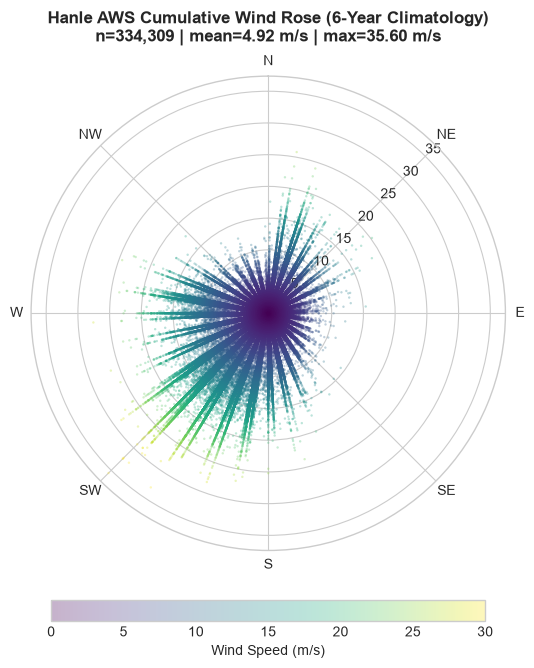

In [4]:
def plot_polar_wind_rose(speeds, directions, title, max_speed=30.0):
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={'polar': True})
    
    theta = np.radians(directions)
    sc = ax.scatter(theta, speeds, c=speeds, cmap='viridis', vmin=0, vmax=max_speed, s=3, alpha=0.3, edgecolors='none')
    
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1) # Clockwise
    ax.set_thetagrids([0, 45, 90, 135, 180, 225, 270, 315], ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
    ax.set_rlabel_position(45)
    
    mean_val = np.mean(speeds)
    max_val = np.max(speeds)
    ax.set_title(f"{title}\nn={len(speeds):,} | mean={mean_val:.2f} m/s | max={max_val:.2f} m/s", 
                 pad=25, fontsize=12, fontweight='bold')
    
    cbar = fig.colorbar(sc, ax=ax, orientation='horizontal', pad=0.08, shrink=0.7)
    cbar.set_label("Wind Speed (m/s)", fontsize=10)
    plt.show()

plot_polar_wind_rose(df_rose['wind_speed'], df_rose['wind_direction'], "Hanle AWS Cumulative Wind Rose (6-Year Climatology)")

## 4. Monthly Wind Roses (Separate for Each Year)

We group and plot the monthly wind roses separately for each year (2020 through 2025) to observe the wind speed and direction patterns month-by-month over the entire 6-year timeseries.

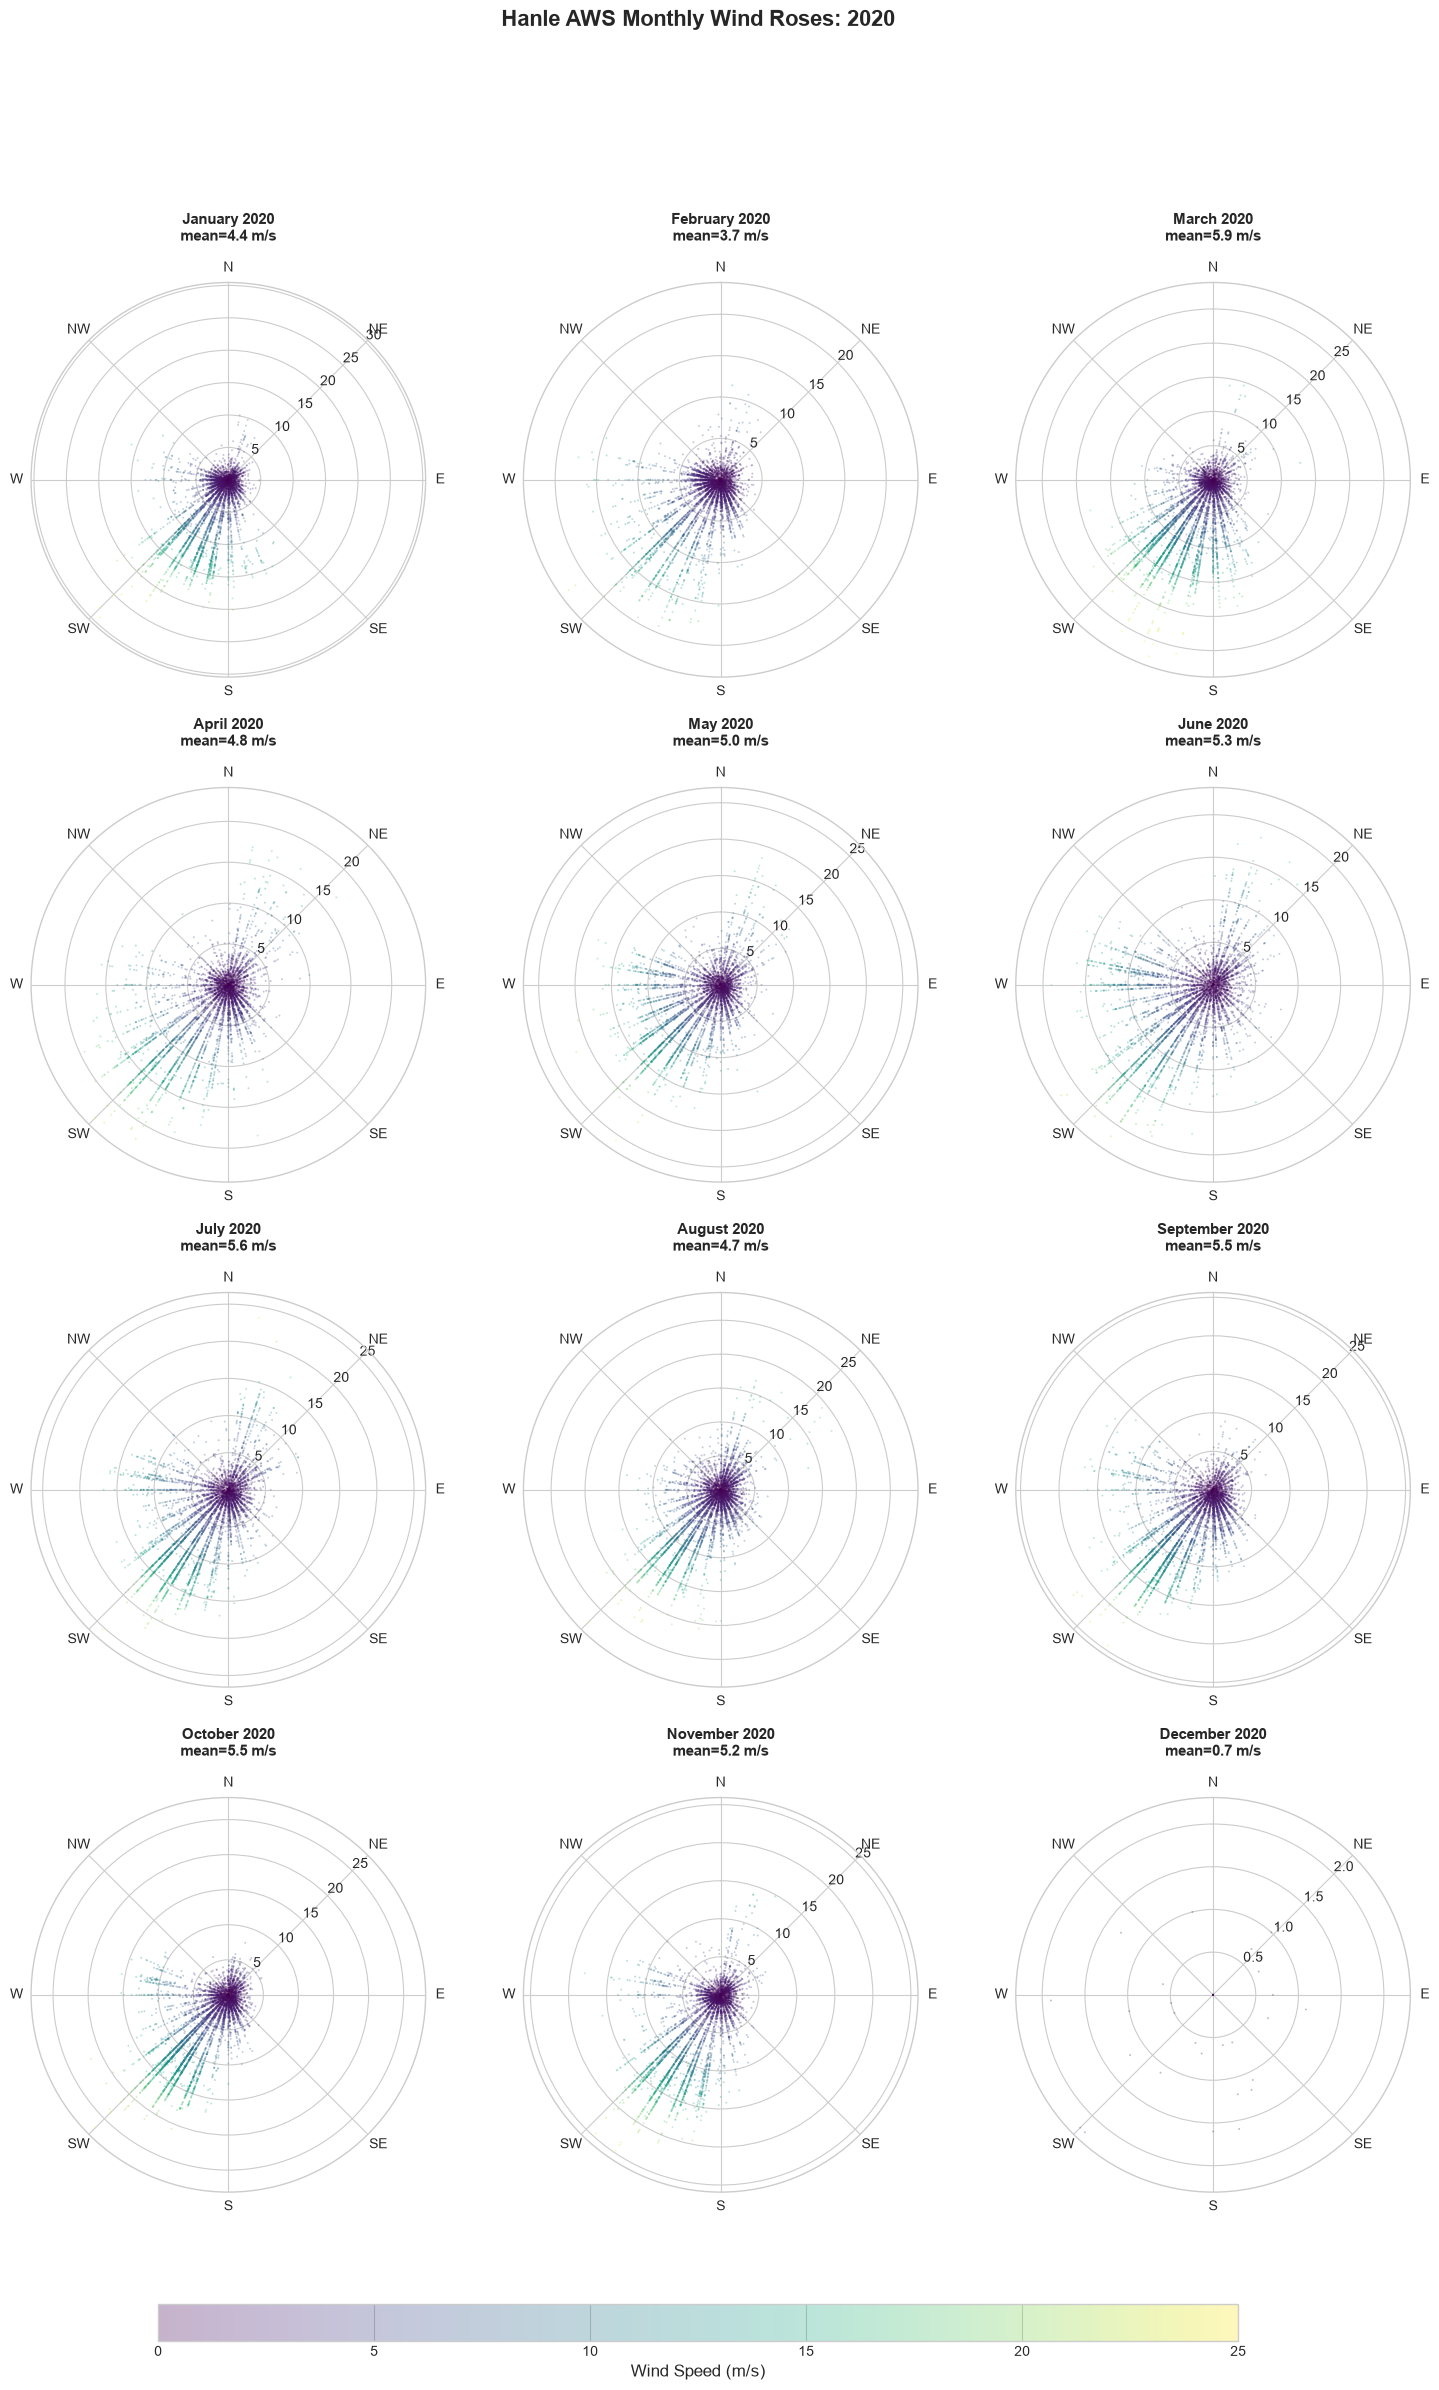

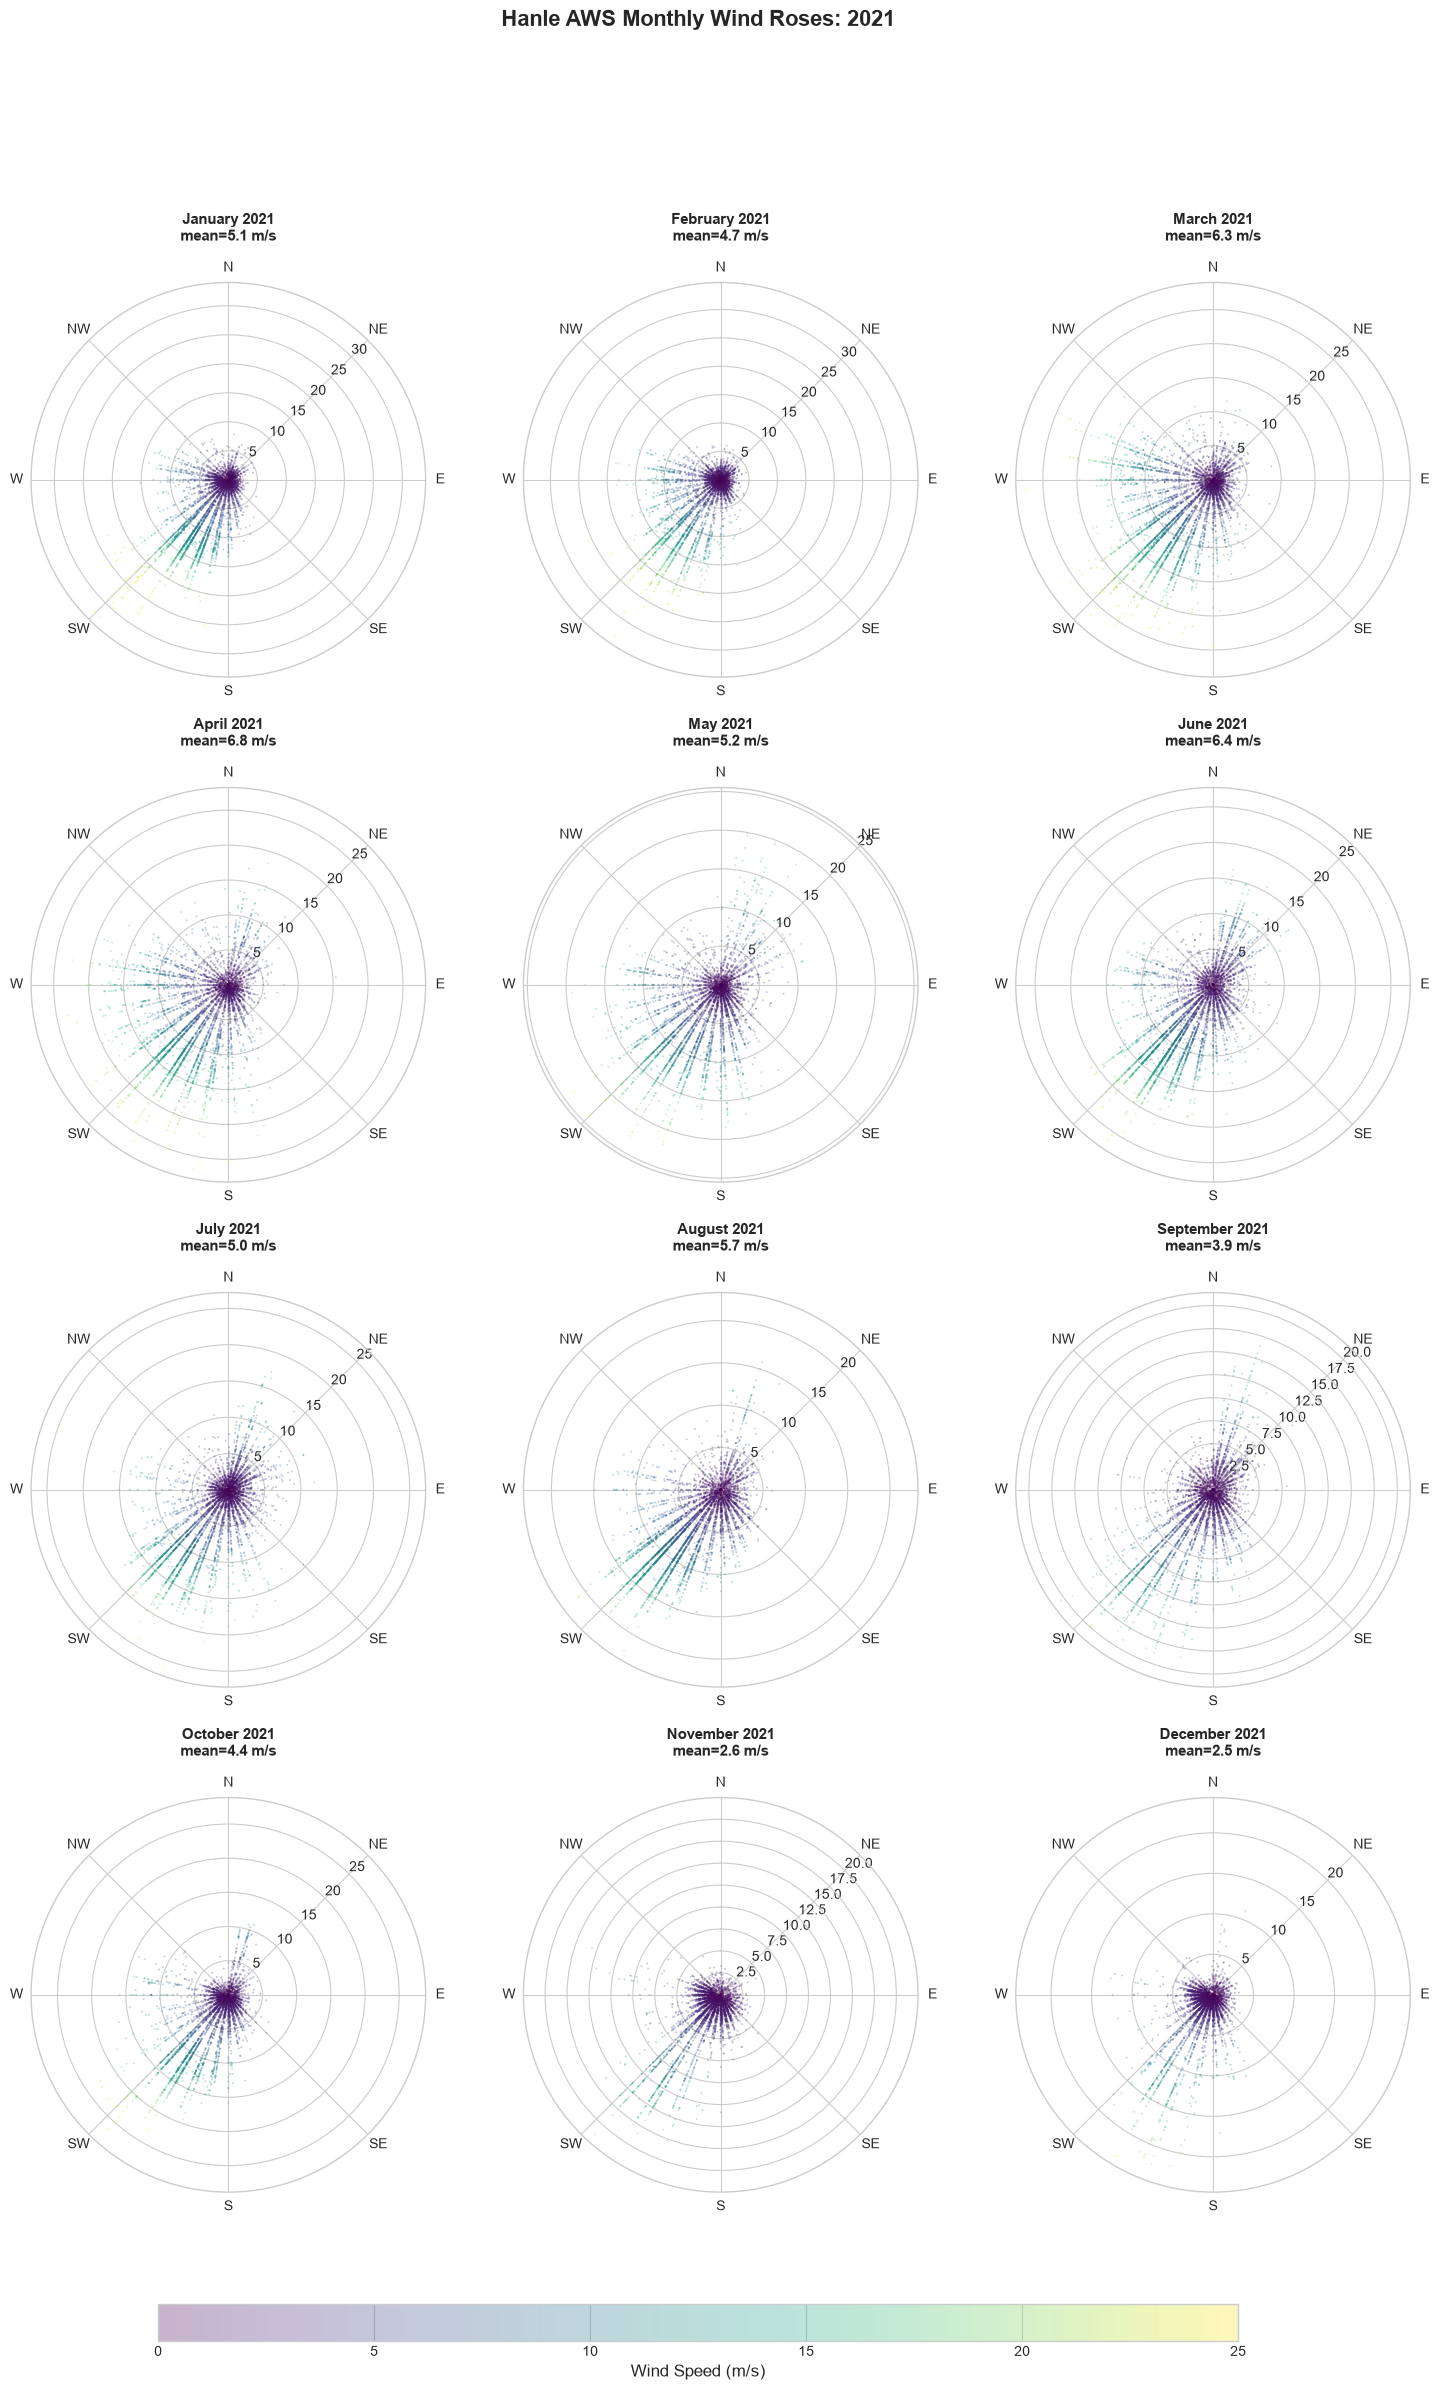

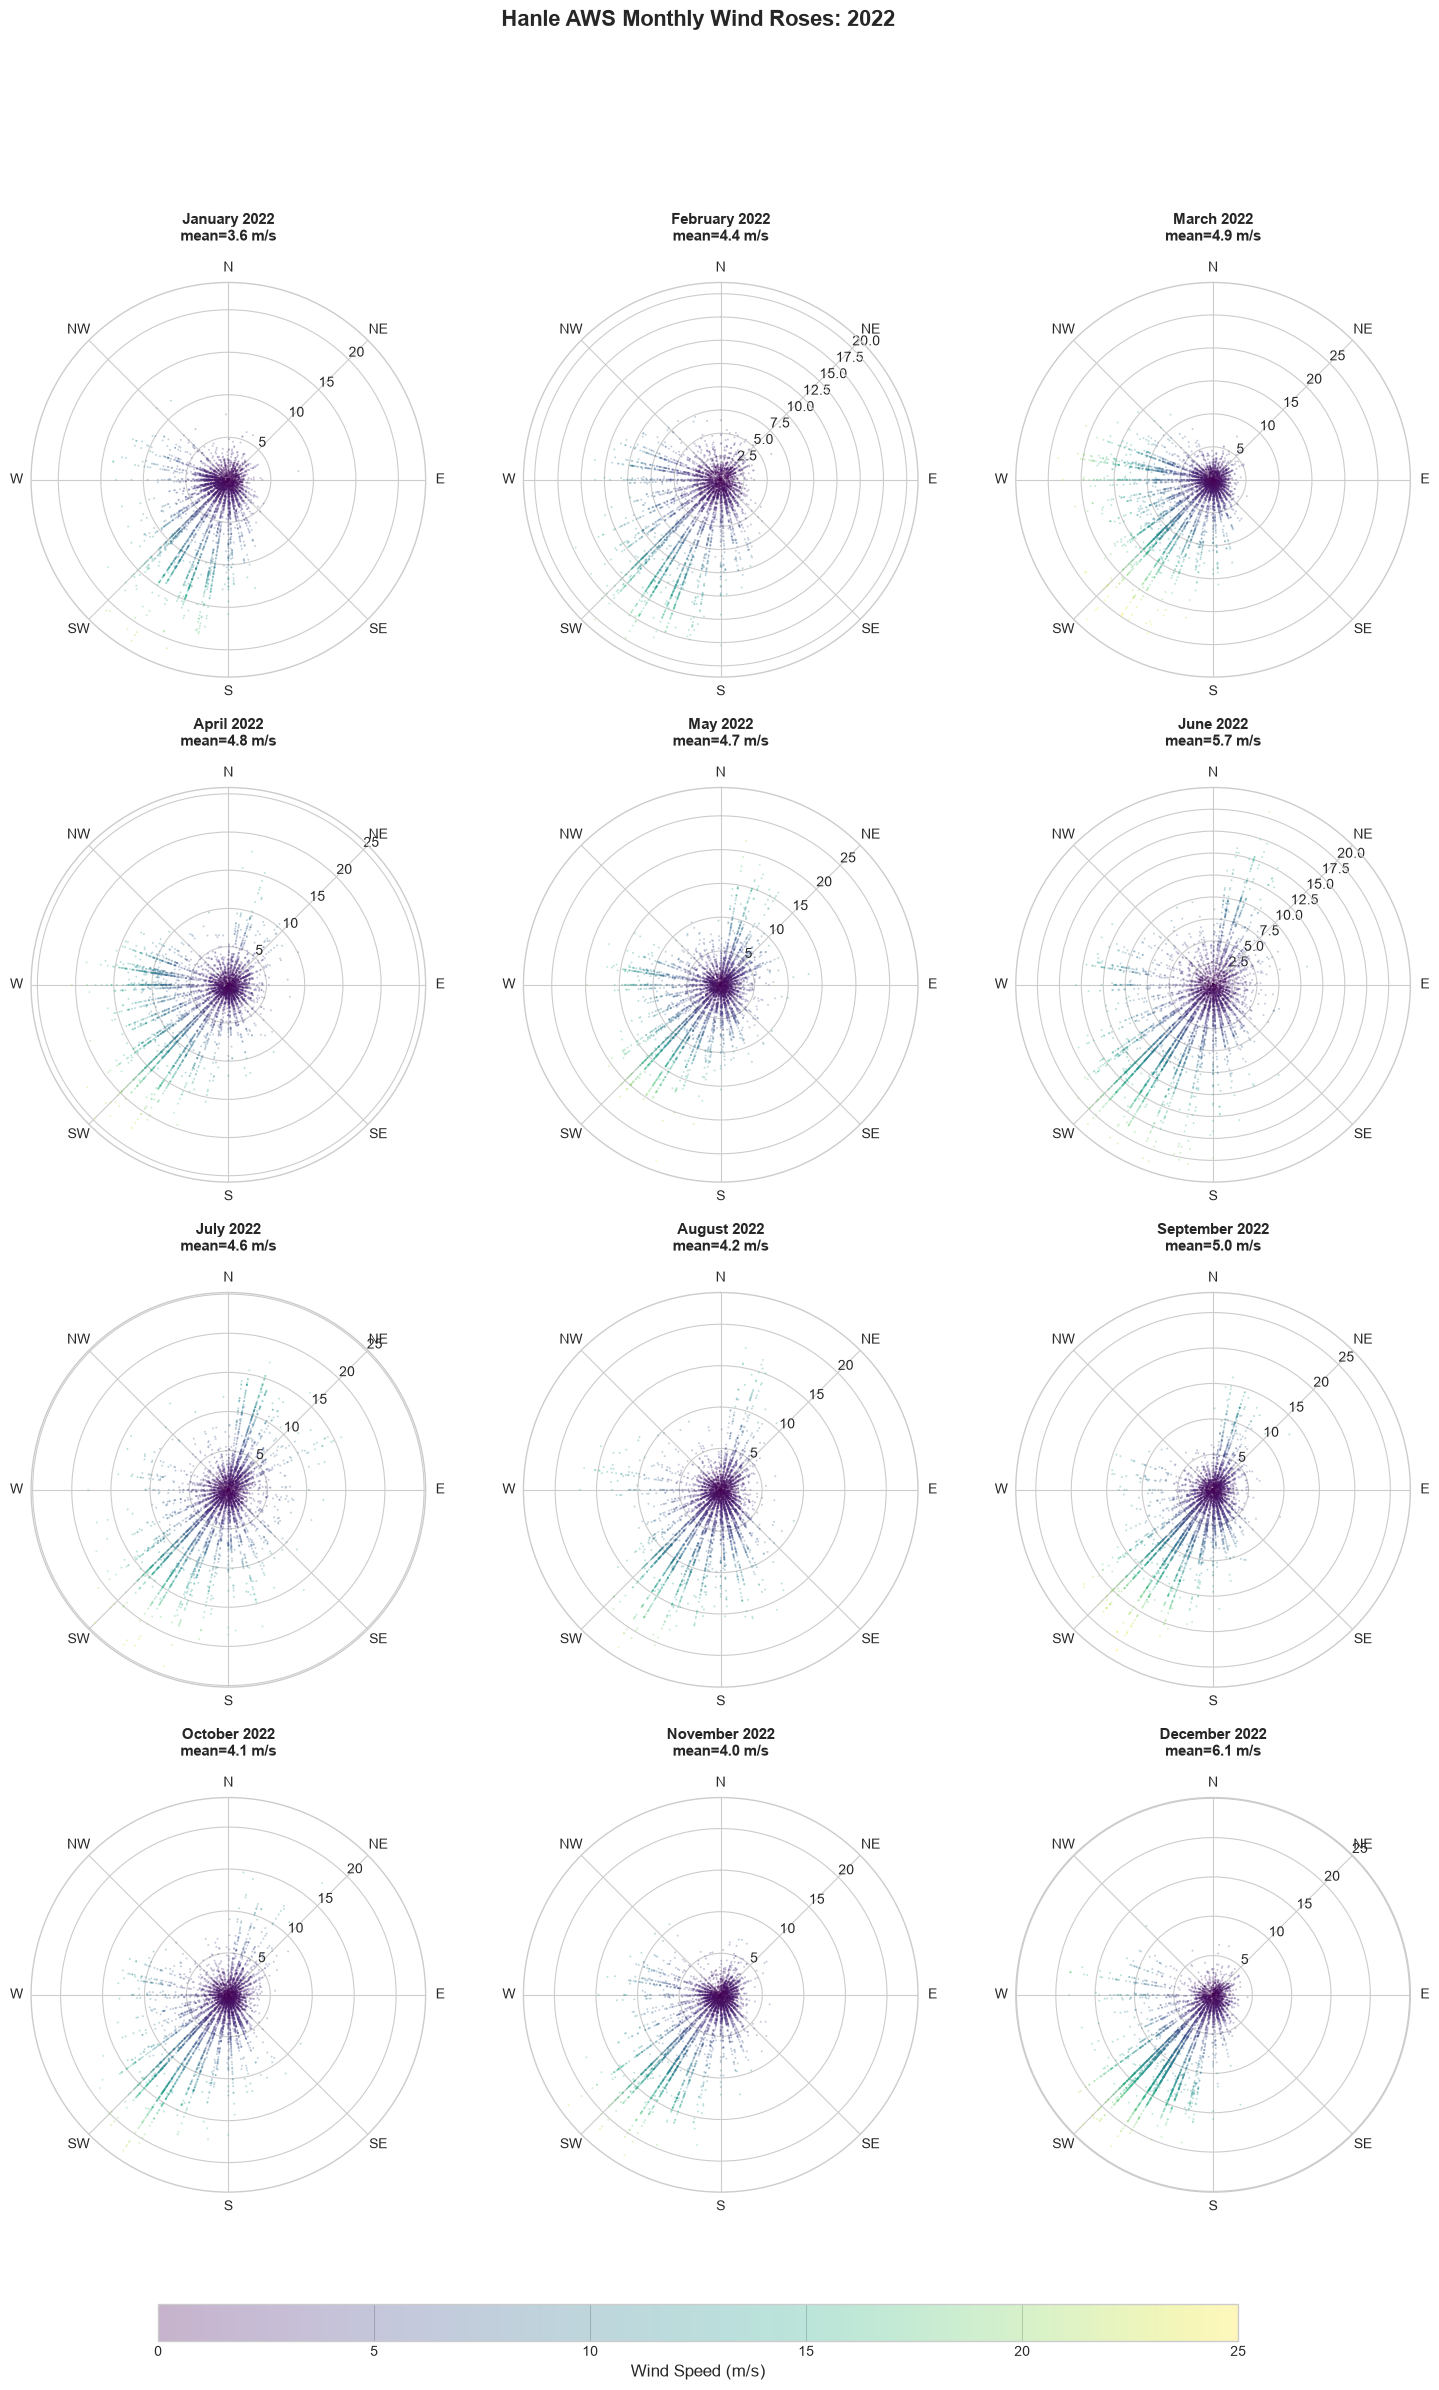

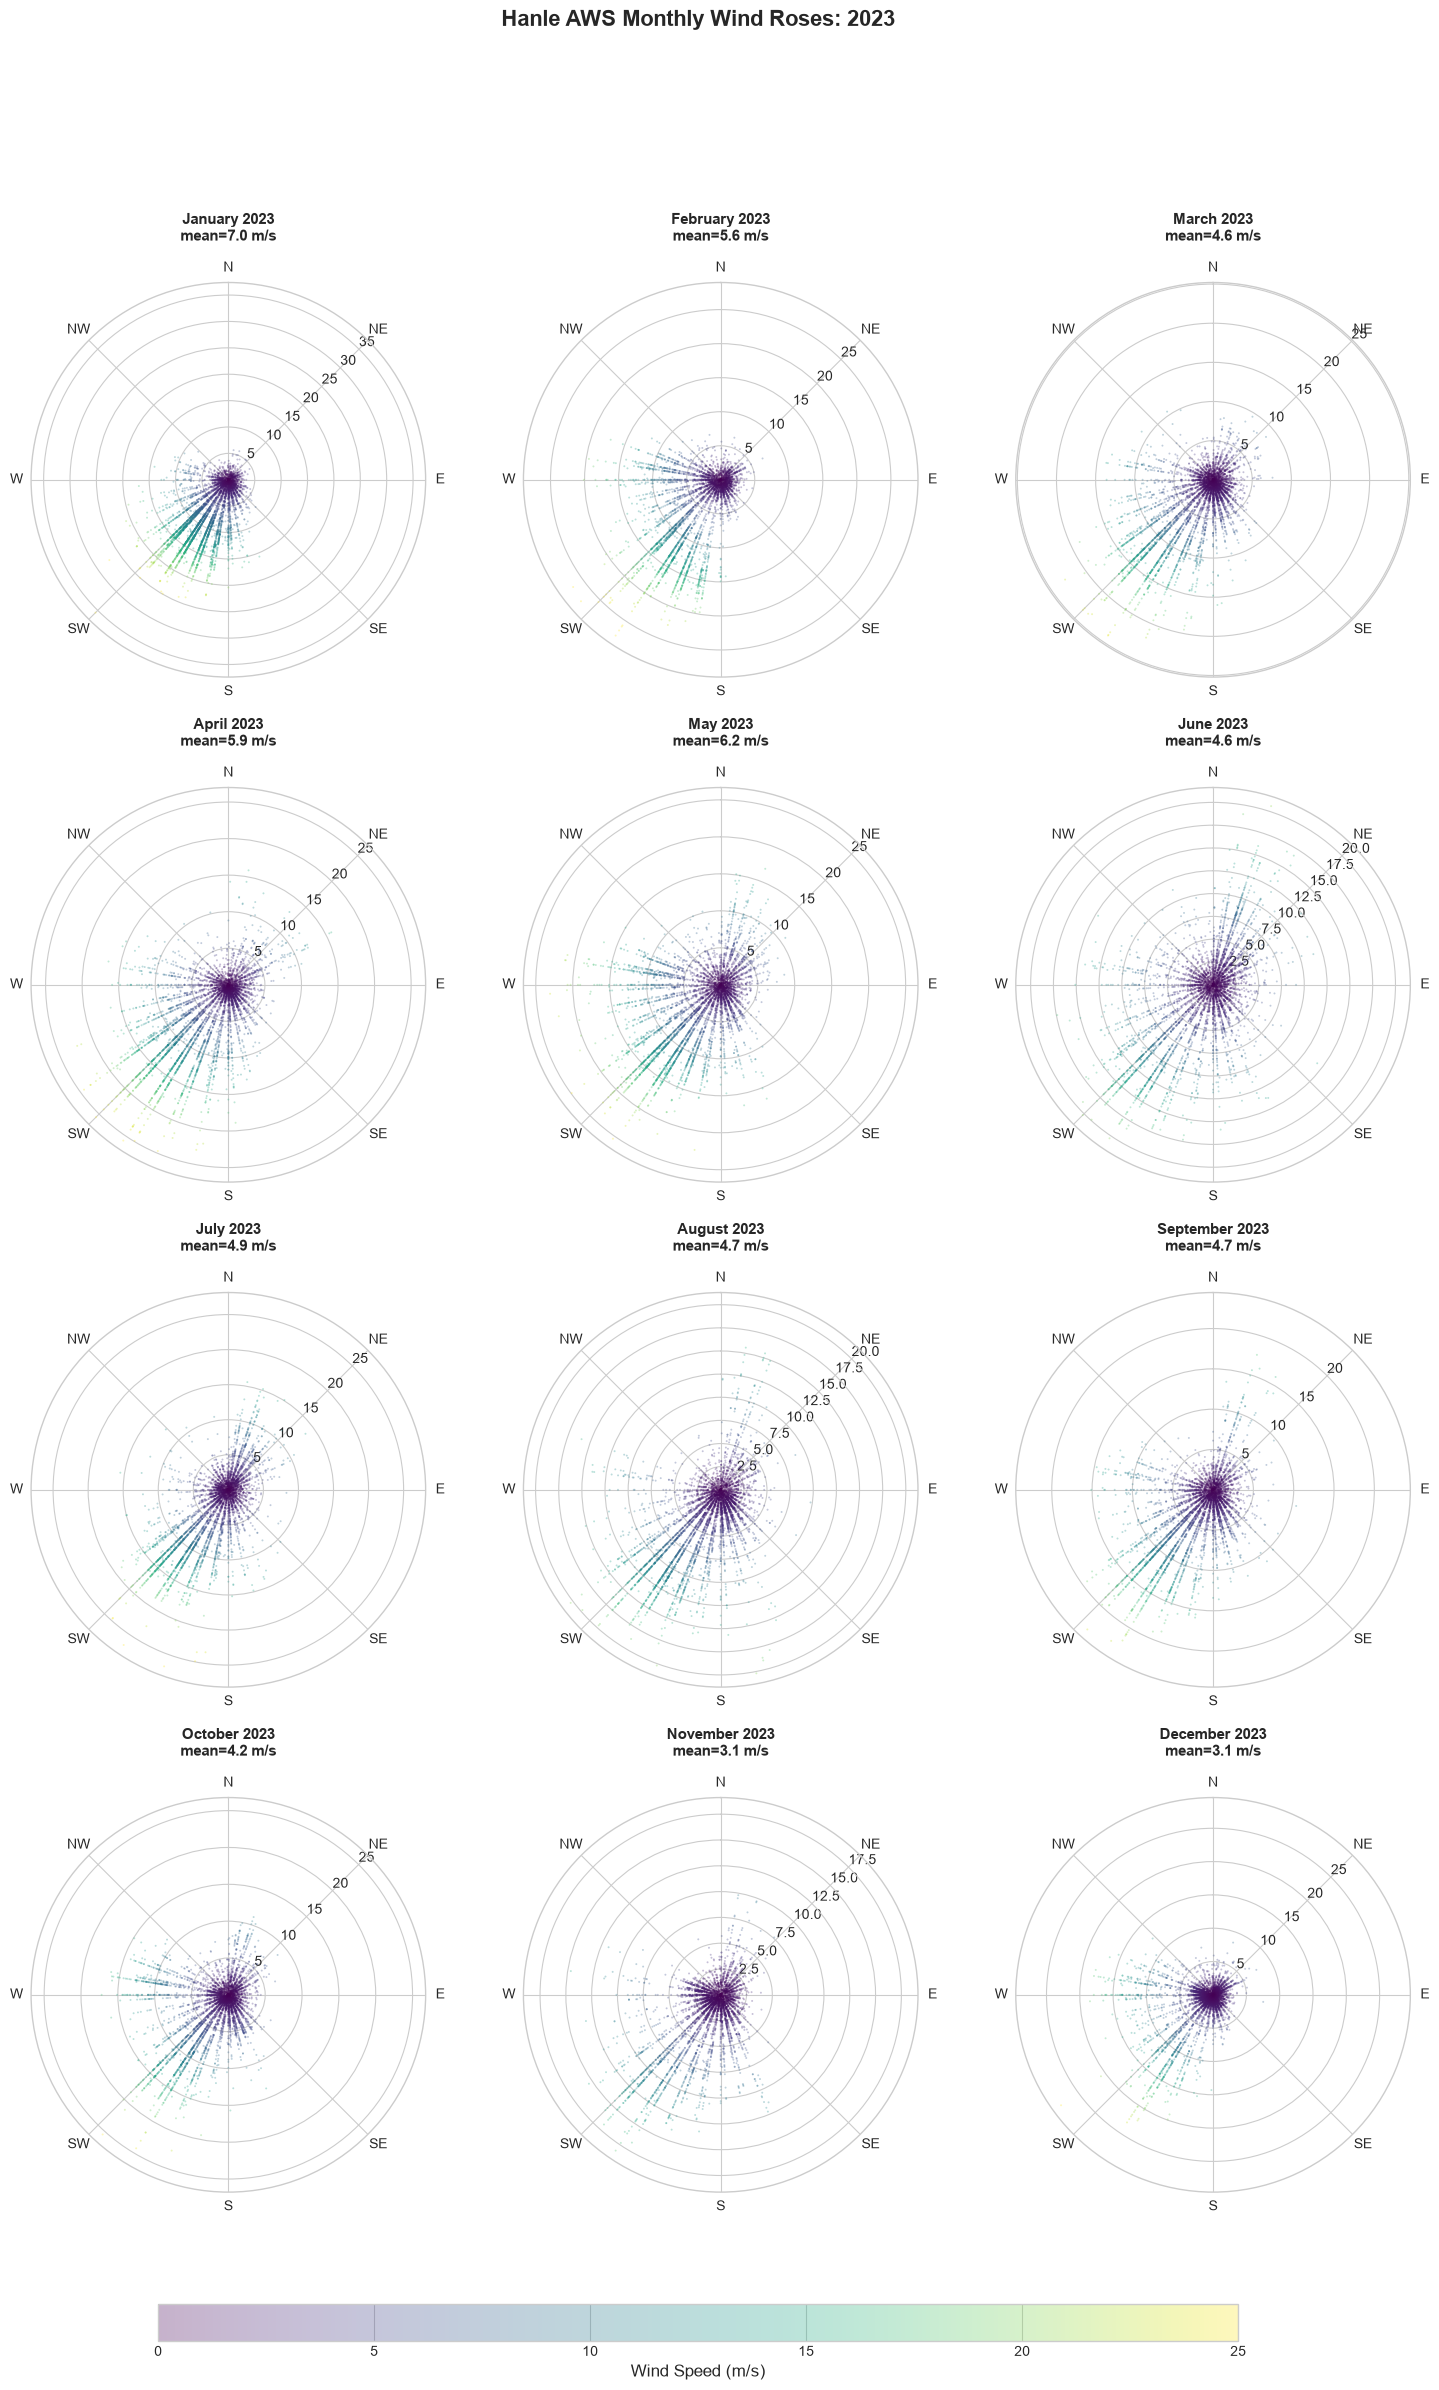

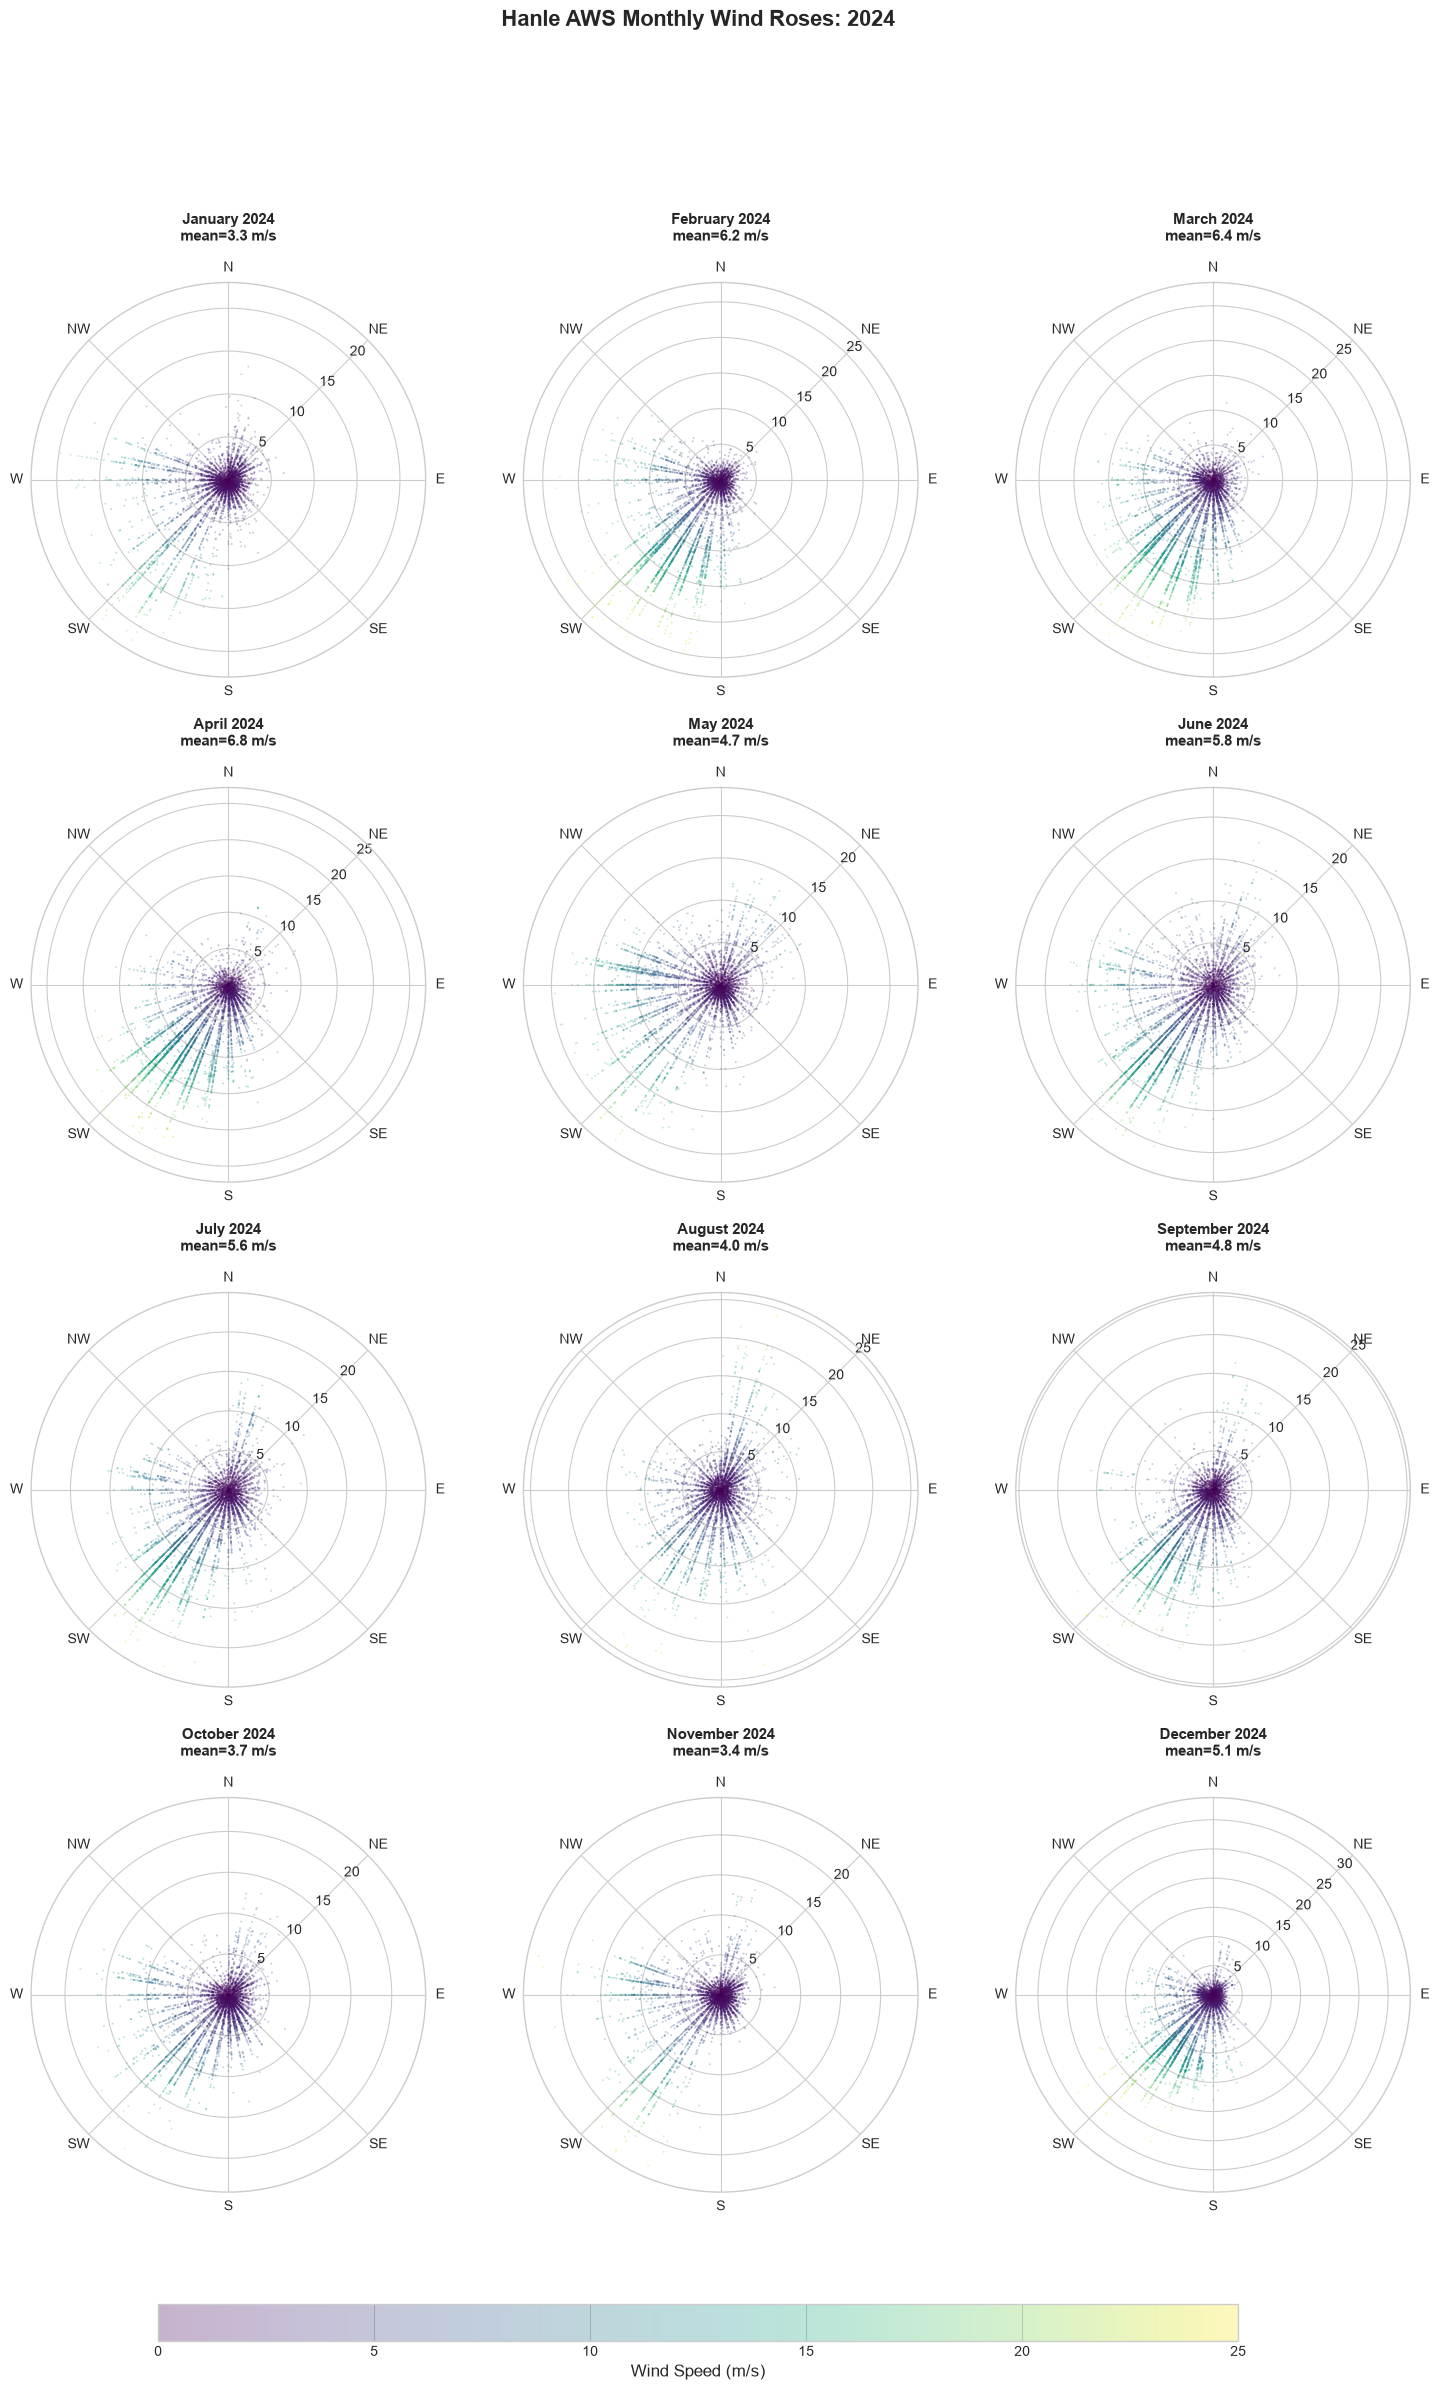

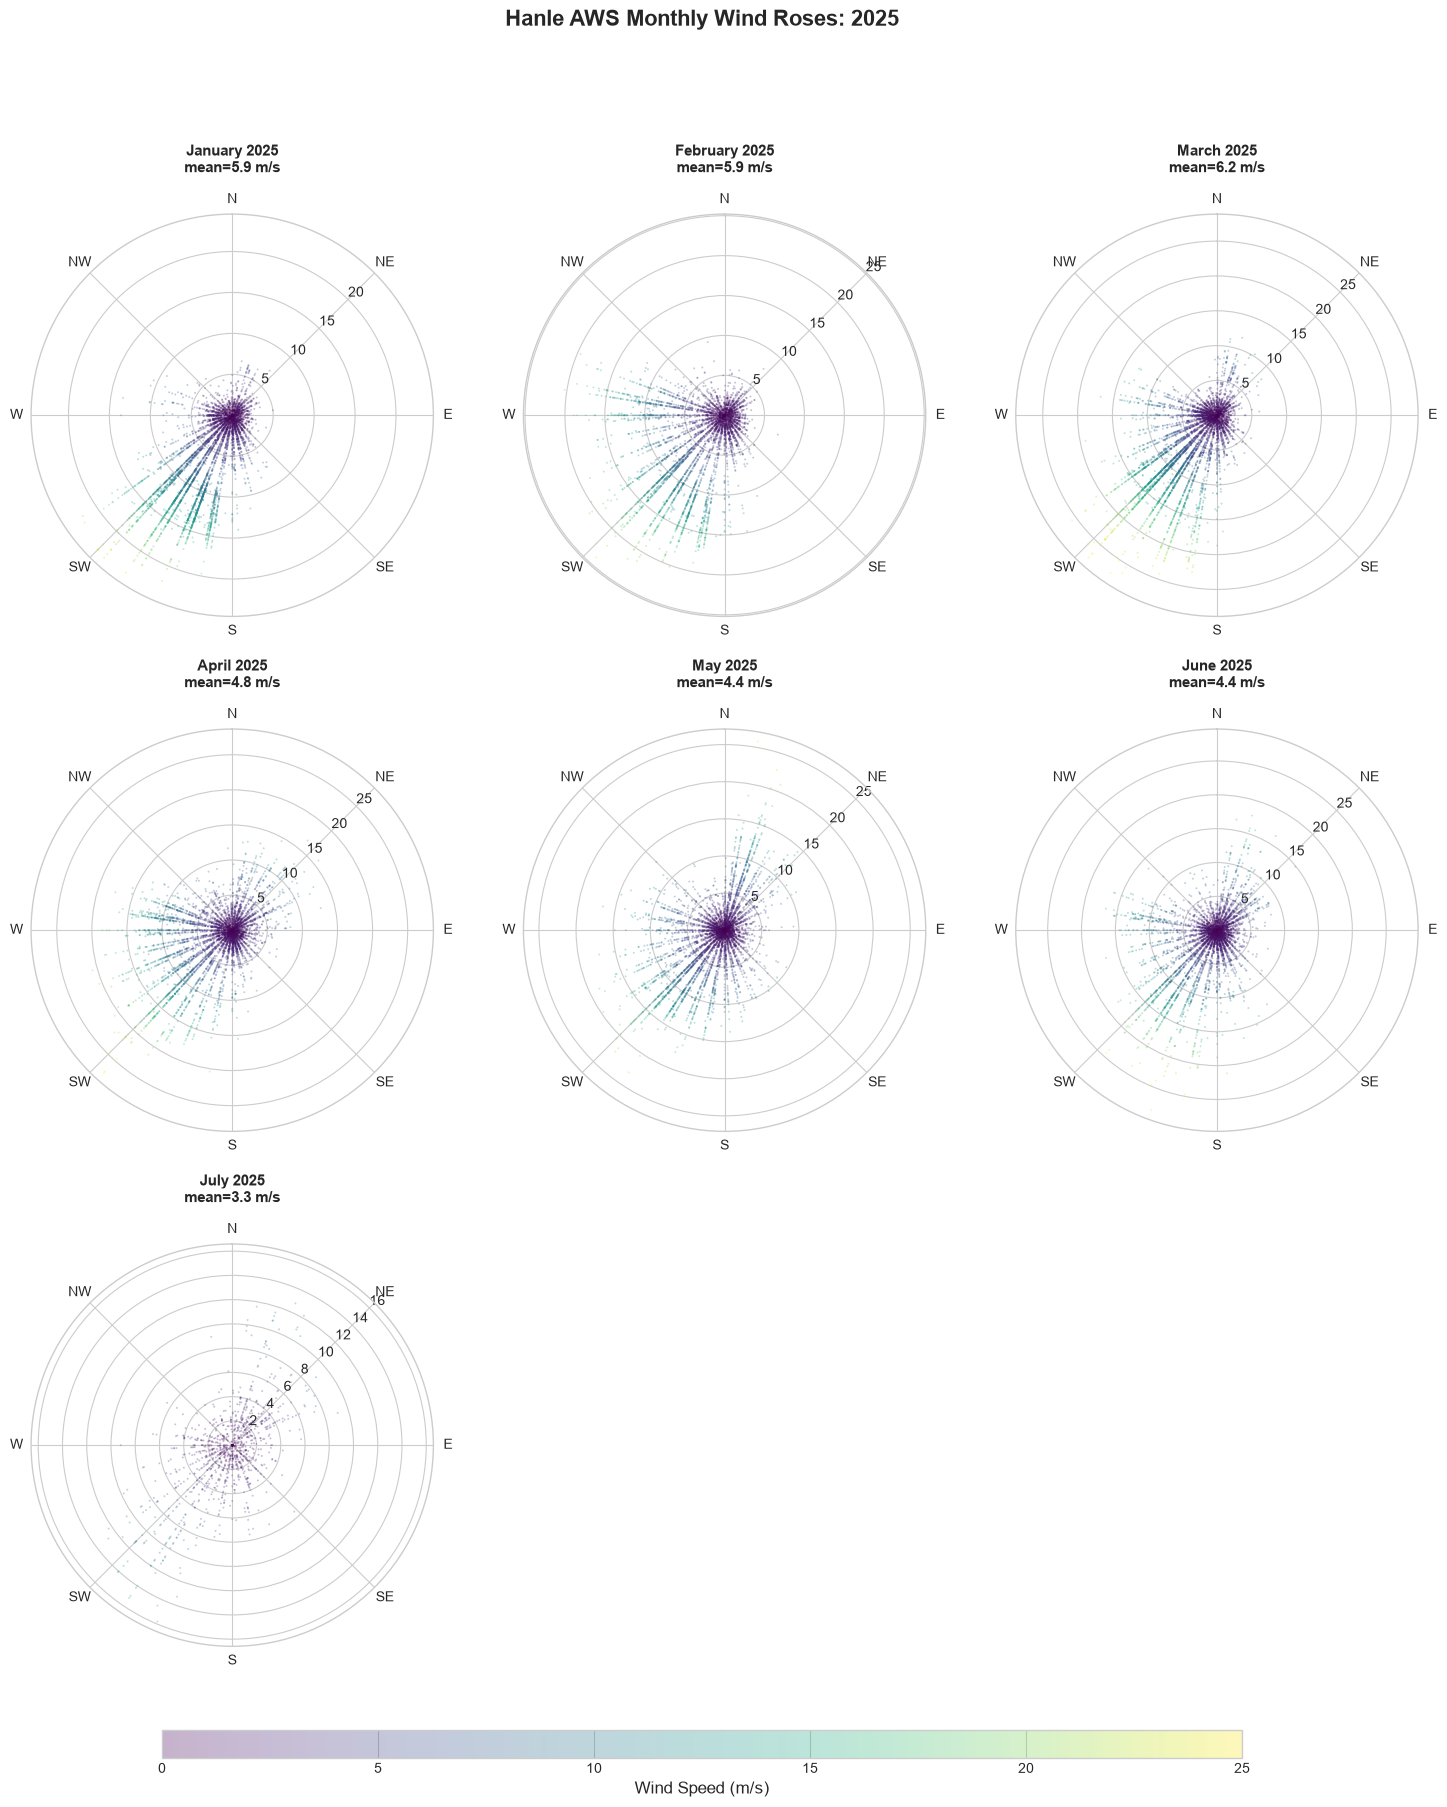

In [5]:
month_names = {1: 'January', 2: 'February', 3: 'March', 4: 'April', 5: 'May', 6: 'June', 
               7: 'July', 8: 'August', 9: 'September', 10: 'October', 11: 'November', 12: 'December'}

df_rose = df_rose.copy()
df_rose['year'] = df_rose['datetime_ist'].dt.year
unique_years = sorted(df_rose['year'].unique())

# We want 12 rows (months) and 6 columns (years)
n_rows = 12
n_cols = len(unique_years)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 2.8 * n_rows), subplot_kw={'polar': True})

sc = None
for col_idx, yr in enumerate(unique_years):
    df_yr = df_rose[df_rose['year'] == yr]
    for row_idx in range(1, 13):
        ax = axes[row_idx - 1, col_idx]
        m_df = df_yr[df_yr['month_num'] == row_idx]
        
        if not m_df.empty:
            theta = np.radians(m_df['wind_direction'])
            sc = ax.scatter(theta, m_df['wind_speed'], c=m_df['wind_speed'], cmap='viridis', vmin=0, vmax=25.0, s=2, alpha=0.3, edgecolors='none')
            
            ax.set_theta_zero_location("N")
            ax.set_theta_direction(-1)
            # Use smaller font sizes to prevent overlap in the 12x6 grid
            ax.set_thetagrids([0, 45, 90, 135, 180, 225, 270, 315], ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'], fontsize=8)
            ax.set_rlabel_position(45)
            ax.tick_params(axis='y', labelsize=7)
            
            m_mean = m_df['wind_speed'].mean()
            ax.set_title(f"{month_names[row_idx]} {yr}\nmean={m_mean:.1f} m/s", pad=10, fontsize=9, fontweight='bold')
        else:
            ax.set_visible(False)

fig.suptitle("Hanle AWS Monthly Wind Roses (12 Months x 6 Years)", fontsize=18, fontweight='bold', y=0.995)
fig.subplots_adjust(hspace=0.45, wspace=0.3)

# Add a single shared colorbar at the bottom of the grid
if sc is not None:
    cbar_ax = fig.add_axes([0.2, 0.015, 0.6, 0.008])
    cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
    cbar.set_label("Wind Speed (m/s)", fontsize=12)

plt.show()

## 5. Multi-Year Timeseries (Resampled to Daily)

To visualize the multi-year trends clearly, we plot the **daily mean wind speed** and the **daily maximum gust** from the pre-calculated daily dataframe.

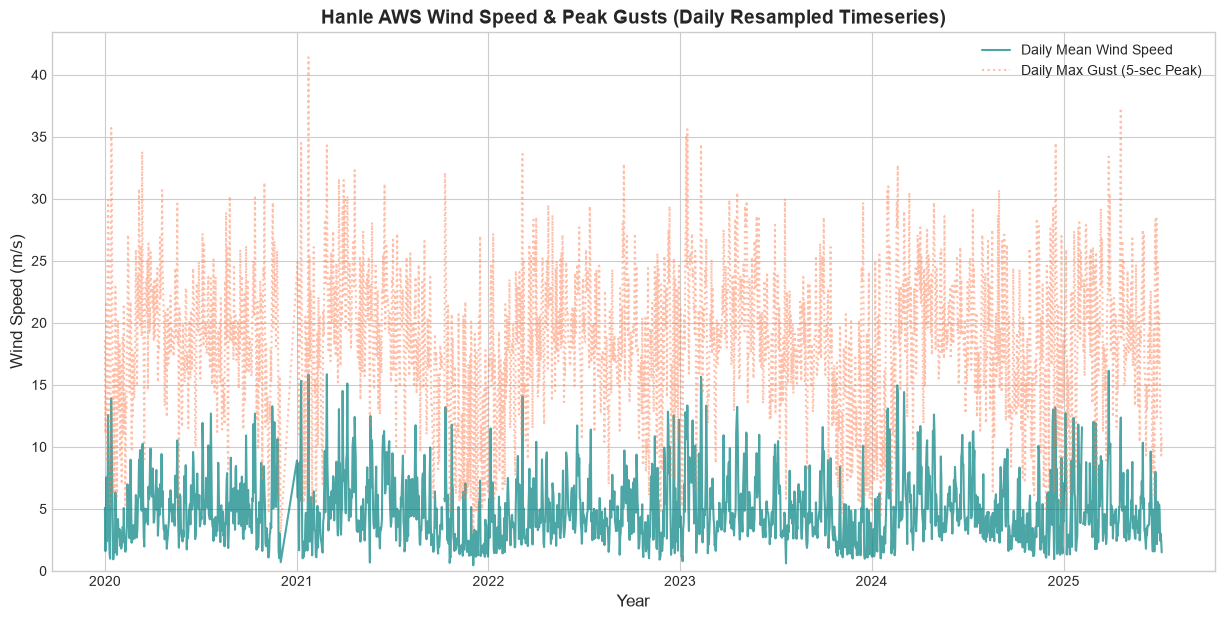

In [6]:
plt.figure(figsize=(15, 7))
plt.plot(df_daily.index, df_daily['wind_speed_mean'], label='Daily Mean Wind Speed', color='teal', alpha=0.7)
plt.plot(df_daily.index, df_daily['wind_speed_max'], label='Daily Max Gust (5-sec Peak)', color='coral', alpha=0.5, linestyle=':')

plt.title("Hanle AWS Wind Speed & Peak Gusts (Daily Resampled Timeseries)", fontsize=14, fontweight='bold')
plt.ylabel("Wind Speed (m/s)", fontsize=12)
plt.xlabel("Year", fontsize=12)
plt.ylim(bottom=0)
plt.legend()
plt.show()

## 6. Seasonal Diurnal Wind Profiles

We group the data into India's official meteorological seasons (as defined by the IMD) to see how the daily wind cycles differ:
- **Winter:** December, January, February
- **Pre-Monsoon:** March, April, May
- **Monsoon:** June, July, August, September
- **Post-Monsoon:** October, November

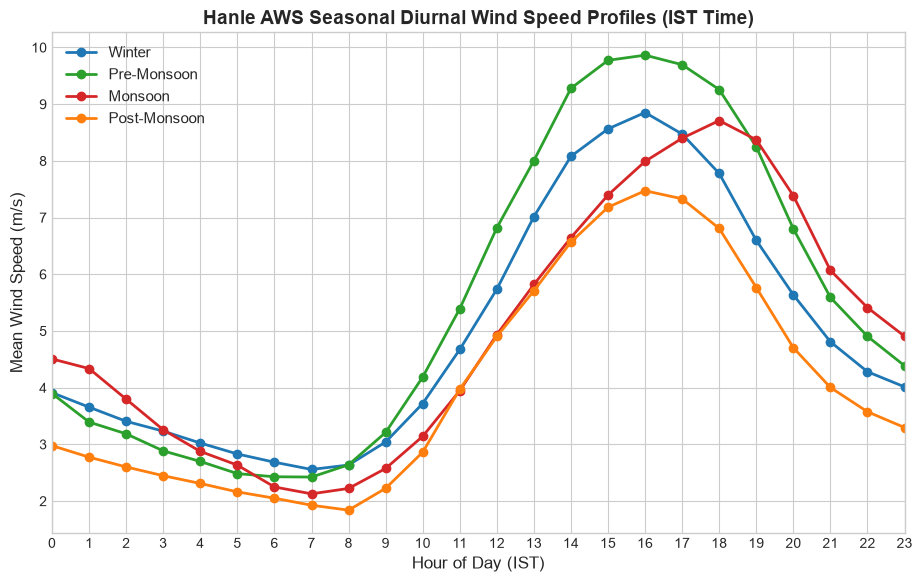

In [7]:
diurnal_seasons = df_rose.groupby(['season', 'hour'])['wind_speed'].mean().unstack(level=0)

plt.figure(figsize=(11, 6.5))
colors = {'Winter': '#1f77b4', 'Pre-Monsoon': '#2ca02c', 'Monsoon': '#d62728', 'Post-Monsoon': '#ff7f0e'}

for season in ['Winter', 'Pre-Monsoon', 'Monsoon', 'Post-Monsoon']:
    if season in diurnal_seasons.columns:
        plt.plot(diurnal_seasons.index, diurnal_seasons[season], marker='o', label=season, color=colors[season], linewidth=2)

plt.title("Hanle AWS Seasonal Diurnal Wind Speed Profiles (IST Time)", fontsize=14, fontweight='bold')
plt.xlabel("Hour of Day (IST)", fontsize=12)
plt.ylabel("Mean Wind Speed (m/s)", fontsize=12)
plt.xticks(range(24))
plt.xlim(0, 23)
plt.legend(fontsize=11)
plt.show()